# Data Processing and Visualization Notebook

## Summary

This jupyter notebook serves as the staging ground and workspace to create data visualizations of the `traffic_metrics.csv`, containing ~30 minutes of simulation data for a cloud server. The goal of the diagrams and charts created will demostrate how the data created will fit into the overall goal of this resource project

### Initialization of Python

Below is the import statements for several key libraries including:
- pandas | Used for data processing
- numpy | Used for any arithmetic that may be required
- matplotlib & seaborn | Used for key data visualization

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv('../traffic_metrics.csv')

# Display the first few rows of the dataset
print(data.head())

                    timestamp  target_rps  average_latency_ms  success_rate  \
0  2026-10-19T12:35:53.739352          55               45.35         100.0   
1  2026-10-19T12:35:54.754775          53               54.08         100.0   
2  2026-10-19T12:35:55.742155          50               42.36         100.0   
3  2026-10-19T12:35:56.756929          55               39.54         100.0   
4  2026-10-19T12:35:57.754658          49               41.24         100.0   

   successful_requests  failed_requests  
0                   55                0  
1                   53                0  
2                   50                0  
3                   55                0  
4                   49                0  


### The Dataset

The CSV file `traffic_metrics.csv` contains several key metrics from the 30 minute simulation, this includes:
- `timestamp` | the exact real life time each data point was captured
- `target_rps` | The target goal of successful requests per second based on requests
- `average_latency_ms` | The time in milliseconds between a request and a response from the server
- `success_rate` | the percent of responses to the target requests
- `successful_requests` | The number of requests that were successfully responsed to
- `failed_requests` | the number of requests that were no responsed to

These data metrics provide a baseline of how the server properly responses to the workload.

### Data Identification

Below, we will be identifying the minimum, median, mean, 75th percentile, and maximum of Throughput and latency

In [39]:
# minimum, median, mean, 75th percentile, and  maximum of throughput (target_rps) and latency (average_latency_ms)

min_throughput = data['target_rps'].min()
median_throughput = data['target_rps'].median()
mean_throughput = data['target_rps'].mean().round(2)
percentile_75_throughput = data['target_rps'].quantile(0.75)
max_throughput = data['target_rps'].max()

min_latency = data['average_latency_ms'].min()
median_latency = data['average_latency_ms'].median()
mean_latency = data['average_latency_ms'].mean().round(2)
percentile_75_latency = data['average_latency_ms'].quantile(0.75)
max_latency = data['average_latency_ms'].max()

# Print the results for throughput
print(f"Throughput (target_rps):")
print(f"Minimum: {min_throughput}")
print(f"Median: {median_throughput}")
print(f"Mean: {mean_throughput}")
print(f"75th Percentile: {percentile_75_throughput}")
print(f"Maximum: {max_throughput}")

# Print the results for latency
print(f"\nLatency (average_latency_ms):")
print(f"Minimum: {min_latency}")
print(f"Median: {median_latency}")
print(f"Mean: {mean_latency}")
print(f"75th Percentile: {percentile_75_latency}")
print(f"Maximum: {max_latency}")

Throughput (target_rps):
Minimum: 15
Median: 52.0
Mean: 56.71
75th Percentile: 72.0
Maximum: 470

Latency (average_latency_ms):
Minimum: 14.32
Median: 47.26
Mean: 52.07
75th Percentile: 64.9675
Maximum: 412.15


### Data Visualization

Our goal below is to create three diagrams:
1. Synthetic Workload Demand Over Time
    - The goal of this chart is to demonstrate the clear sine-wave cycles ranging from 15 to 85 RPS with sharp traffic spikes that reach up to 470 RPS. This will provide the exact workload characterisitcs that will be needed to evaluate the predictive models.
2. Microservice Processing latency Over Time
    - This graph displays response latency that is tracked linearly during normal operation ranging from 15 to 80 ms, but will jump up to ~400ms during taffic bursts, this illustrates the queueing delay experienced before dynmaic allocation kicks in
3. Throughput vs Latency
    - This scatter plot will be to identify a potential linear relationship between incoming request volume and processing delay

Text(0, 0.5, 'Latency (average_latency_ms)')

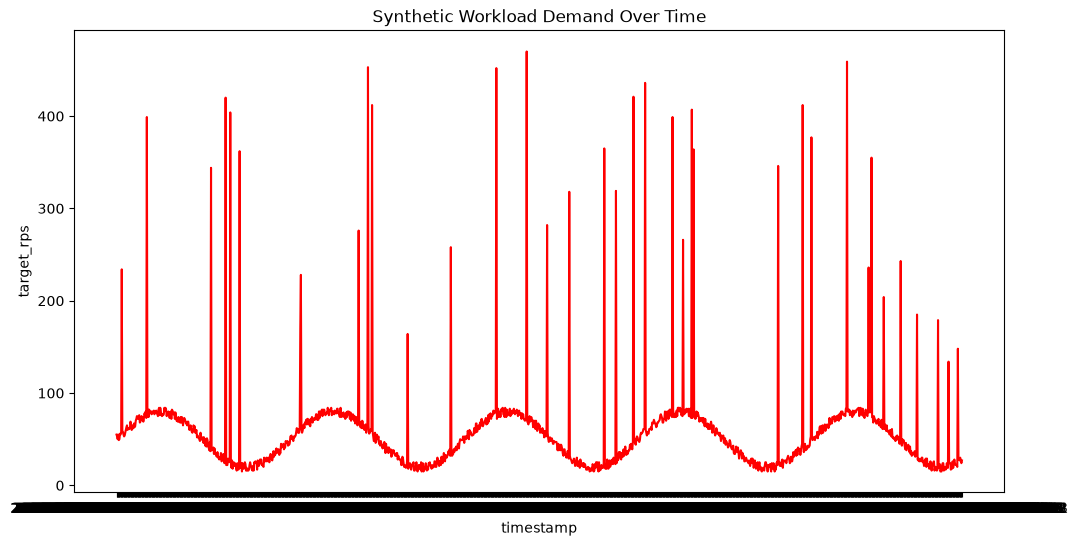

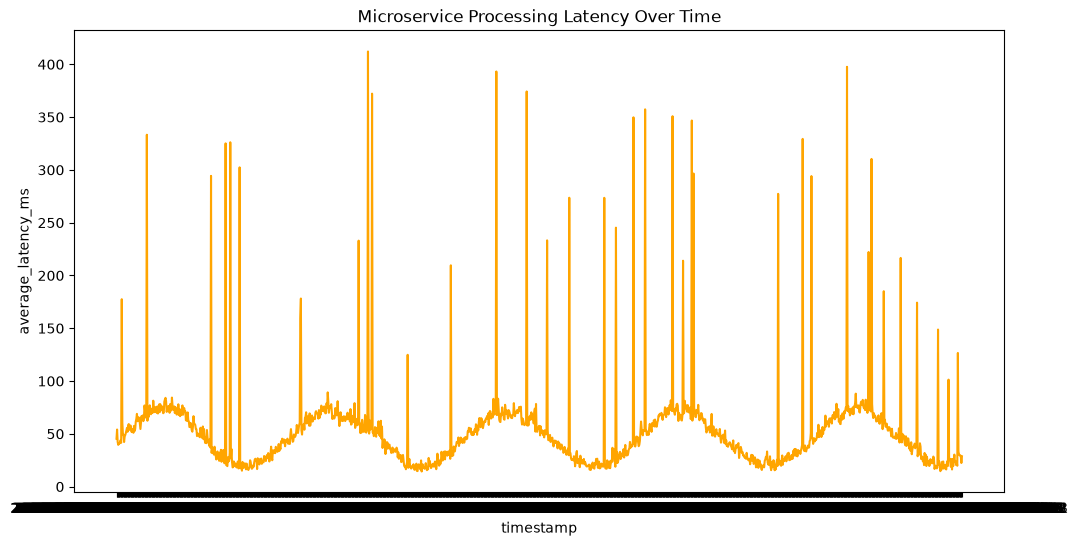

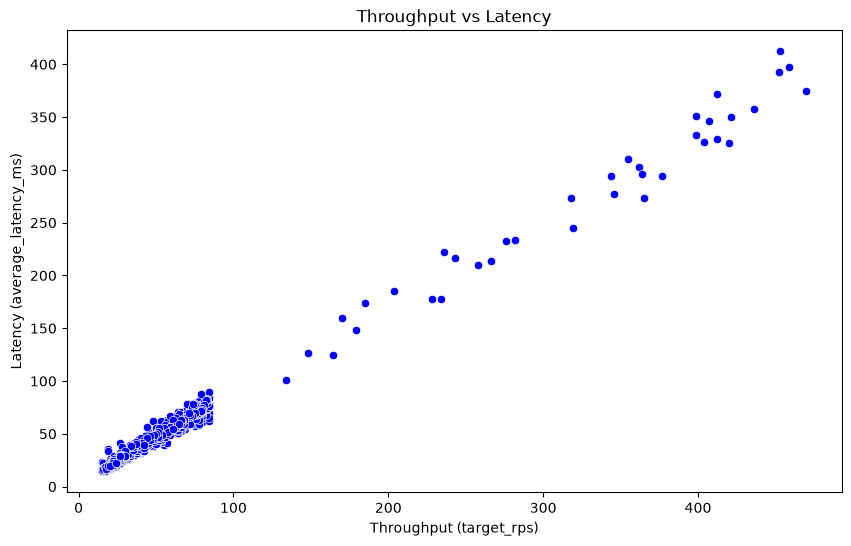

In [40]:
# Create a Time Series Plot to visualize the throughput over time
plt.figure(figsize=(12, 6))
plt.title('Synthetic Workload Demand Over Time')
sns.lineplot(x='timestamp', y='target_rps', data=data, color='red')

# Create a Time Series Plot to visualize the latency over time
plt.figure(figsize=(12, 6))
plt.title('Microservice Processing Latency Over Time')
sns.lineplot(x='timestamp', y='average_latency_ms', data=data, color='orange')


# Create a scatter plot to visualize the relationship between throughput and latency
plt.figure(figsize=(10, 6))
sns.scatterplot(x='target_rps', y='average_latency_ms', data=data, color='blue')
plt.title('Throughput vs Latency')
plt.xlabel('Throughput (target_rps)')
plt.ylabel('Latency (average_latency_ms)')


### Seaborn Data Evaluation

Using seaborn, this gives us the ability to review more complex aspects of the data, primarily these diagrams will focus on these following statistics:

1. Workload & Latency Distribution Models
    - These will show the probability density and frequency distribution of incoming RPS or response latencies, which can identify operational modes for our predictive model
2. Time-Series Trend Model
    - Using a lineplot with rolling window smoothing, we will aggregate trendlines ove relapsed time, allowing use to overlay raw RPS values alongside a 10-second moving average to visually separate underlying cyclic demand from noise spikes.

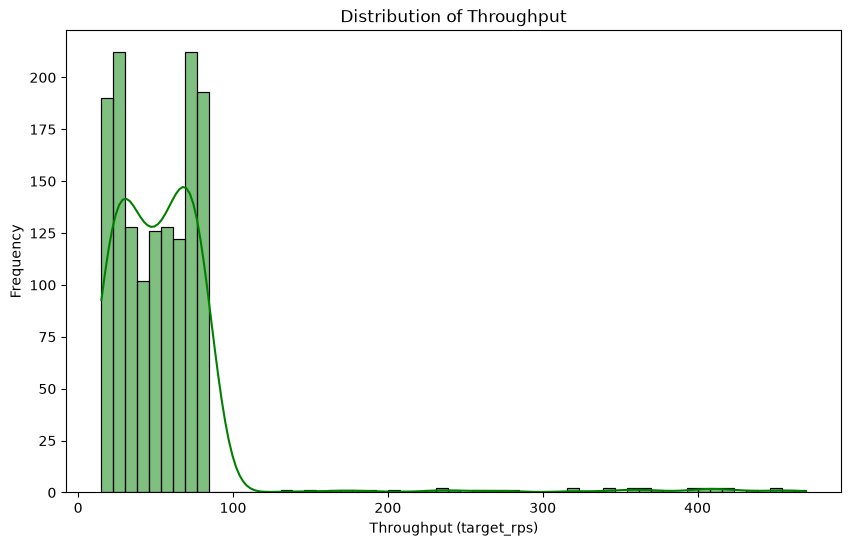

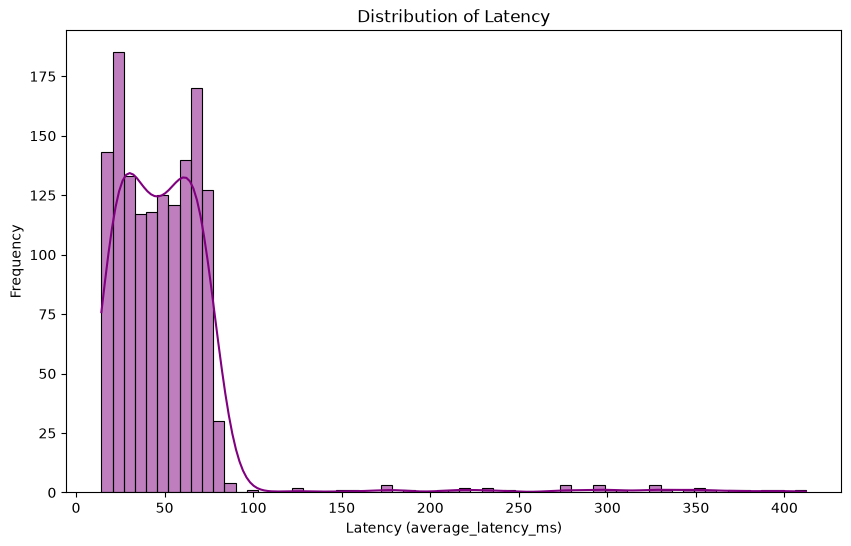

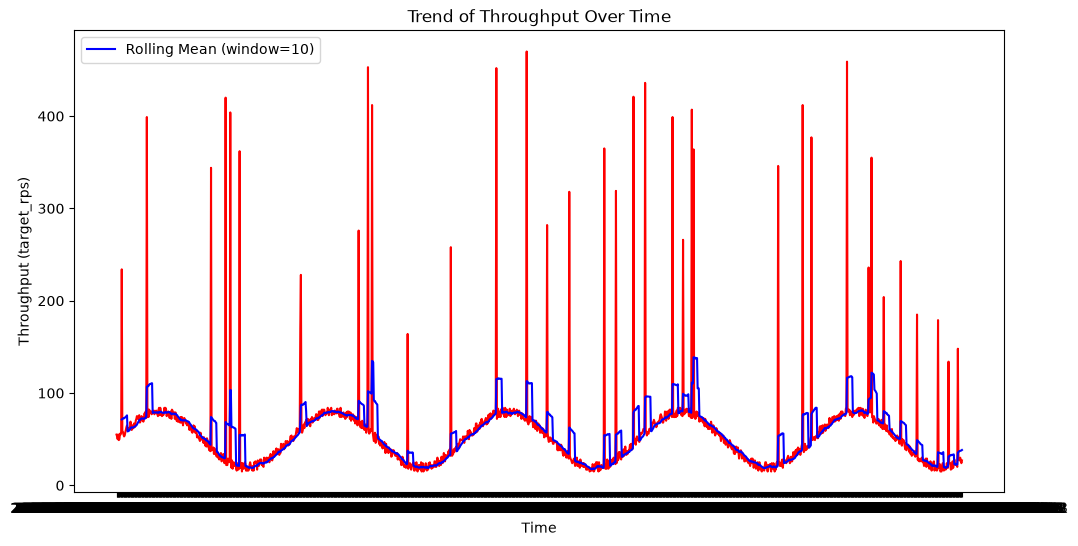

In [42]:
# create a histogram to visualize the probability density and frequency distribution of throughput 
plt.figure(figsize=(10, 6))
sns.histplot(x='target_rps', data=data, color='green', kde=True)
plt.title('Distribution of Throughput')
plt.xlabel('Throughput (target_rps)')
plt.ylabel('Frequency')

# create a histogram to visualize the probability density and frequency distribution of latency
plt.figure(figsize=(10, 6))
sns.histplot(x='average_latency_ms', data=data, color='purple', kde=True)
plt.title('Distribution of Latency')
plt.xlabel('Latency (average_latency_ms)')
plt.ylabel('Frequency')

# create a time series trend line model to visualize the trend of throughput over time using rolling window smoothing
plt.figure(figsize=(12, 6))
sns.lineplot(x='timestamp', y='target_rps', data=data, color='red')
plt.title('Trend of Throughput Over Time')
plt.xlabel('Time')
plt.ylabel('Throughput (target_rps)')
data['target_rps'].rolling(window=10).mean().plot(color='blue', label='Rolling Mean (window=10)')
plt.legend()


## Summary

The exploratory data visualizations reveal insights into both workload characteristics and microservice performance across the 1,450 collected timesteps. The synthetic workload displays a bimodal distribution with baseline traffic oscillating between 15 and 85 requests per second along a sine wave. Intermittent traffic spikes are overlaid onto this base demand, driving peak throughput up to a peak of 470 RPS. Feature correlation analysis confirms a near perfect linear relationship between targe RPS, successful request throughput, and average processing latency, indicating that system response times scale directly with incoming request volume.

From a capacity and performance standpoint, response times remain stable under standard operating condition but experience severe queuing delays during burst traffic. Under baseline loads below 70 RPS, average response times stay consistently between 14.32 ms and 50 ms. However, once traffic enters anything above 150 RPS range, lantency increases dramatically, reaching an extreme peak of 412.15 ms with an overall mean of 52.07 ms. This rapid rise in tail latency during traffic bursts highlights the clear threshold for incorporating real-time dynamic scaling via Online Convex Optimization to maintain SLA targets.